# Permit sources: exploration and handling audit

## tl;dr

The source has 851,077 permit records. The frozen analysis
extract has 200,453 records, including every permit
type in the reporting window. Demolition PINs are absent through 2025; recent
populated PINs are 10-digit parcel identifiers. Condo parking/storage and sparse
commercial characteristics prevent naive PIN or row counting.

The exploration came before final reporting. Exact requests and source hashes
are in data/raw; the decision log and field dictionaries are in docs.

## Context & Methods

Question: can gross permitted dwellings overstate net additions over existing
housing stock? Reporting window: 2023-01-01 through 2026-10-08. Current 2023 wards.
Record-level linkage focuses on Wards 32, 1, and 47. Complete years and partial
2026 are distinguished. This notebook reads the frozen, inspectable evidence.

### Key Assumptions

Issue dates measure authorizations subject to source status semantics, not
completion. Tax-year characteristics are estimates, not daily physical-stock
observations. Missing stock stays unknown. Same-address demolition linkage is
bounded to five years and complex scopes remain unresolved.

In [1]:
from pathlib import Path
import sys, json, csv
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.json').exists() and (p / 'data/raw').is_dir())
sys.path.insert(0, str(ROOT / 'code'))
from source_io import read, RAW, DERIVED
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':140,'savefig.dpi':160})
COLORS = ['#244f68', '#bd873b', '#98a4ad', '#dbc69d']
FIGURES = ROOT / 'report/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.savefig(path, bbox_inches='tight', facecolor='white', metadata={'Software':'Chicago net-permits reproducible analysis'})
    try:
        from IPython.display import display, Image
        display(Image(filename=str(path)))
    except ImportError:
        print('Saved figure:', path.name)
    plt.close(fig)
def show_rows(rows, fields, limit=12):
    import io
    buffer=io.StringIO()
    writer=csv.writer(buffer)
    writer.writerow(fields)
    for row in rows[:limit]: writer.writerow([row.get(k) for k in fields])
    print(buffer.getvalue())
config = read(ROOT / 'config.json')
stats = read(DERIVED / 'report_statistics.json')


Matplotlib is building the font cache; this may take a moment.


## Data

### 1. Source and extract coverage

In [2]:
print(json.dumps({k:v for k,v in stats.items() if k!='focus_summary'}, indent=2))
print('Partition checks:', read(DERIVED / 'permit_extraction_checks.json'))
print('Geography and duplicate-key checks:', read(DERIVED / 'permit_geography_profile.json'))

{
  "source_records": 851077,
  "source_first_issue": "2006-01-03",
  "source_last_issue": "2026-10-21",
  "downloaded_permit_records": 200453,
  "reporting_window_permit_records": 124831,
  "ward_features": 50,
  "cancelled_recent_records": 357,
  "recent_missing_coordinates": 2001,
  "recent_outside_wards": 708,
  "commercial_rows": 68113,
  "commercial_rows_with_apt": 0,
  "condo_rows": 2851,
  "condo_parking_storage_rows": 1089,
  "city_published_gross": 15253,
  "city_published_sfh": 1367,
  "new_projects_partial_only": 0
}
Partition checks: {'checks': [{'partition': 'permits_records_2010_2019_demolition', 'expected': 12485, 'downloaded': 12485, 'where': "issue_date >= '2010-01-01T00:00:00' AND issue_date < '2020-01-01T00:00:00' AND permit_type='PERMIT - WRECKING/DEMOLITION'"}, {'partition': 'permits_records_2017', 'expected': 11469, 'downloaded': 11469, 'where': "issue_date >= '2017-01-01T00:00:00' AND issue_date < '2018-01-01T00:00:00' AND permit_type in('PERMIT - NEW CONSTRUCTI

### 2. Review source grain and data dictionaries

In [3]:
inventory=list(csv.DictReader((DERIVED / 'source_inventory.csv').open()))
show_rows(inventory, ['name','dataset_id','fields','dictionary_file'])
print(json.dumps(read(DERIVED / 'assessor_quality_profile.json'), indent=2))

name,dataset_id,fields,dictionary_file
Assessor - Parcel Addresses,3723-97qp,18,docs/data_dictionaries/assessor_address_schema.json
Assessor - Commercial Valuation Data,csik-bsws,76,docs/data_dictionaries/assessor_commercial_schema.json
Assessor - Residential Condominium Unit Characteristics,3r7i-mrz4,25,docs/data_dictionaries/assessor_condominium_schema.json
Assessor - Residential Single and Multi-Family Improvement Characteristics,x54s-btds,44,docs/data_dictionaries/assessor_residential_schema.json
Assessor - Parcel Universe (Historical),nj4t-kc8j,124,docs/data_dictionaries/assessor_universe_schema.json
Building Permits,ydr8-5enu,116,docs/data_dictionaries/permit_schema.json
Boundaries - Wards (2023-),p293-wvbd,8,docs/data_dictionaries/wards_2023_schema.json

{
  "addresses": {
    "downloaded": 20432,
    "unique": 11492,
    "duplicate_keys": 8940,
    "conflicting_keys": 0
  },
  "universe": {
    "downloaded": 11562,
    "unique": 11562,
    "duplicate_keys": 0,
    "conflicting_

## Results

### 3. Parcel identifiers are unevenly available

Saved figure: source-pin-coverage.png
year,permit_type,records,with_pin10,pinCoverage,cancelled
2023,NEW CONSTRUCTION,1224,799,0.6527777777777778,3
2023,RENOVATION/ALTERATION,6428,6338,0.9859987554449284,14
2023,WRECKING/DEMOLITION,615,0,0.0,0
2024,NEW CONSTRUCTION,1244,826,0.6639871382636656,1
2024,RENOVATION/ALTERATION,6185,6146,0.9936944219886823,6
2024,WRECKING/DEMOLITION,635,0,0.0,0
2025,NEW CONSTRUCTION,1460,1033,0.7075342465753425,5
2025,RENOVATION/ALTERATION,5505,5458,0.9914623069936421,4
2025,WRECKING/DEMOLITION,661,0,0.0,0
2026,NEW CONSTRUCTION,1247,837,0.6712109061748196,1
2026,RENOVATION/ALTERATION,4240,4223,0.9959905660377358,1
2026,WRECKING/DEMOLITION,522,21,0.040229885057471264,0



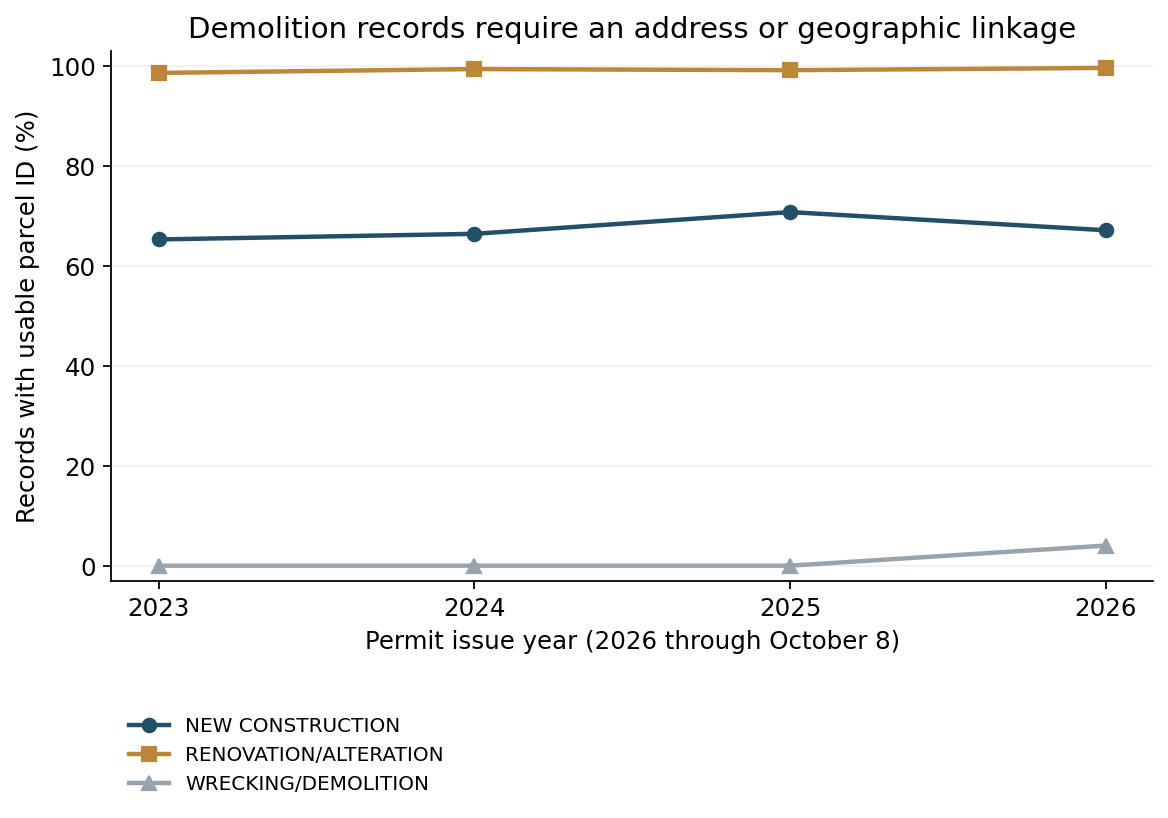

In [4]:
coverage=read(DERIVED / 'recent_field_coverage.json')
fig, ax=plt.subplots(figsize=(8.4,4.3))
for i,kind in enumerate(['NEW CONSTRUCTION','RENOVATION/ALTERATION','WRECKING/DEMOLITION']):
    subset=sorted([r for r in coverage if r['permit_type']==kind],key=lambda r:r['year'])
    ax.plot([r['year'] for r in subset],[r['pinCoverage']*100 for r in subset],label=kind,color=COLORS[i],marker=['o','s','^'][i],linewidth=2)
ax.set(xlabel='Permit issue year (2026 through October 8)',ylabel='Records with usable parcel ID (%)',ylim=(-3,103),xticks=[2023,2024,2025,2026],title='Demolition records require an address or geographic linkage')
ax.grid(axis='y',alpha=.18);ax.legend(frameon=False,fontsize=9,loc='center left',bbox_to_anchor=(0,-.33))
show_figure(fig,'source-pin-coverage')
show_rows(coverage,['year','permit_type','records','with_pin10','pinCoverage','cancelled'])

Demolition coverage is observed as zero through 2025. A missing
parcel link is not evidence that no housing was removed. New-construction PINs
also have substantial missingness, while renovation coverage is much higher.

### 4. Distinguish parking from homes and entities from parcels

In [5]:
qa=read(DERIVED / 'assessor_quality_profile.json')
condo=qa['condominium_characteristics'];total=qa['condominium']['unique']
print('Condo parking/storage:',condo['parking_or_storage_rows'],'of',total,'historical rows')
print('Commercial fields:',qa['commercial_characteristics'])
print('Multicard and tieback cases:',qa['residential_characteristics']['multicard_rows'],qa['residential_characteristics']['tieback_rows'])
assert qa['commercial_characteristics']['rows_with_apt']==0
assert qa['universe']['conflicting_keys']==0
assert qa['residential']['conflicting_keys']==0

Condo parking/storage: 1089 of 2851 historical rows
Commercial fields: {'rows': 68113, 'entity_year_keys': 66836, 'entity_year_keys_with_multiple_rows': 472, 'rows_with_apt': 0, 'rows_with_tot_units': 13355, 'rows_with_model': 802}
Multicard and tieback cases: 944 105


### 5. Record-level scope decisions are retained

In [6]:
reviews=list(csv.DictReader((ROOT / 'docs/review_decisions.csv').open()))
show_rows(reviews,['permit_number','kind','after_units','delta_text','basis'],limit=10)

permit_number,kind,after_units,delta_text,basis
101078038,new_construction,40,,Full building description states new 40 unit five story mixed-use building; R-2 occupancy; no word residential required.
101073305,new_construction,8,,Full building description states five story eight unit mixed-use building; R-2 occupancy.
101020371,new_construction,6,,Proposed three story six unit mixed-use building with first-floor commercial space and residential program.
100976942,new_construction,5,,New four story five unit masonry building with rooftop deck and five-car residential garage; interpretation reviewed from complete description.
100963472,new_construction,1,,Description states addition/new construction from existing basement through second floor on existing single-family home; retain one-for-one reconstruction as a project.
101022458,other,,,Steel pergola on garage rooftop; residential occupancy is context and adds no dwelling.
101072658,other,,,Nail salon buildout within an existing mixed-

## Takeaways

The sources support a reproducible pilot, not a naive citywide PIN subtraction.
Correct handling requires building/card aggregation, condo-use filtering, staged
project linkage, explicit status and date rules, and unresolved-case retention.
The commercial apartment field is unusable in the retrieved Chicago years.
Read the companion net-results notebook for estimates and coverage limits.